In [2]:
import pandas as pd
df=pd.read_csv('Telco-Churn.csv')
df['TotalCharges']=pd.to_numeric(df['TotalCharges'], errors='coerce')
df=df.dropna(subset=['TotalCharges'])
df=df.drop(columns=['customerID'])
df['Churn']=df['Churn'].map({'Yes':1, 'No':0})
print(df['TotalCharges'].isnull().sum())
print(df.shape)
print(df.head())
print(df.info())
print(df['Churn'].value_counts())

0
(7032, 20)
   gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female              0     Yes         No       1           No   
1    Male              0      No         No      34          Yes   
2    Male              0      No         No       2          Yes   
3    Male              0      No         No      45           No   
4  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   
1              Yes 

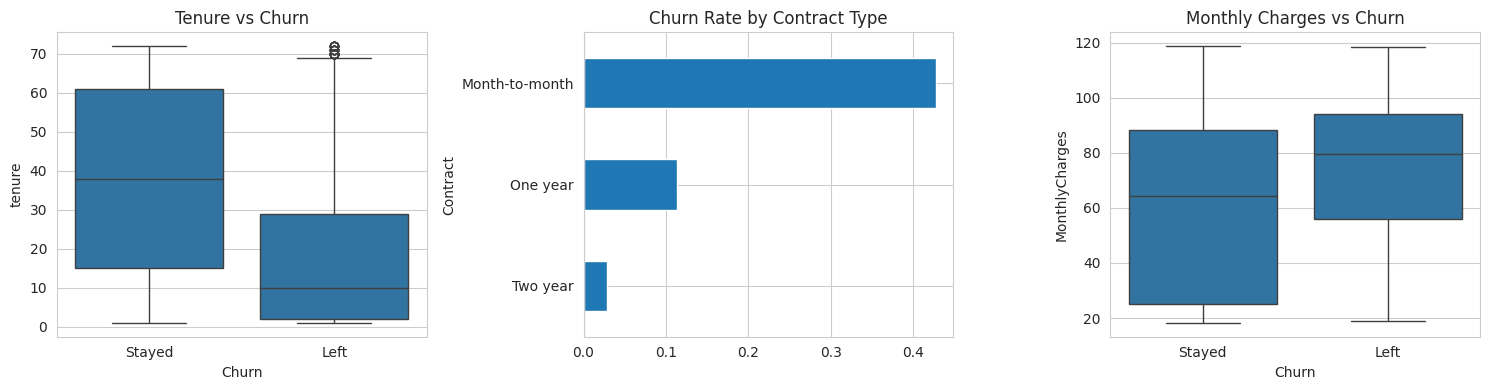

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(data=df, x='Churn', y='tenure', ax=axes[0])
axes[0].set_title('Tenure vs Churn')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Stayed', 'Left'])

contract_churn = df.groupby('Contract')['Churn'].mean().sort_values()
contract_churn.plot(kind='barh', ax=axes[1])
axes[1].set_title('Churn Rate by Contract Type')

sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=axes[2])
axes[2].set_title('Monthly Charges vs Churn')
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(['Stayed', 'Left'])

plt.tight_layout()
plt.show()

In [7]:
X = df.drop(columns=['Churn'])
y = df['Churn']

print(X.shape)
print(y.shape)

(7032, 19)
(7032,)


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape)
print(X_test.shape)

(5625, 19)
(1407, 19)


In [9]:
!pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
  Using cached joblib-1.5.3-py3-none-any.whl.metadata (5.5 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 4.4 MB/s  0:00:02m 4.7 MB/s eta 0:00:01
Using cached joblib-1.5.3-py3-none-any.whl (309 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.7/37.7 MB 5.3 MB/s  0:00:07 eta 0:00:010:01:01
Using cached threadpoolctl-3.6.0-py3-none-any.whl (18 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [scikit-learn]0m 3/4 [scikit-learn]

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python3.10 -m pip install --upgrade pip


In [11]:
cat_cols = X_train.select_dtypes(include='object').columns.tolist()
num_cols = X_train.select_dtypes(exclude='object').columns.tolist()

print("Categorical columns:", cat_cols)
print("Numeric columns:", num_cols)

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numeric columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [12]:
X_train_encoded = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)

print(X_train_encoded.shape)
print(X_test_encoded.shape)

(5625, 30)
(1407, 30)


In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train_encoded[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test_encoded[num_cols])

In [15]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

print("Training complete")

Training complete


In [16]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print()
print(classification_report(y_test, y_pred))
print()
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8052594171997157

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.81      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.81      0.80      1407


[[918 115]
 [159 215]]
